# PROJECT WORK


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Progetto GEODATA/dataset_training.csv')
df.head()

,FID,ID,DTM_elevat,roughness,slope,dissection,surfaceare,distance,litologia,Value
0,4,11_judge,13.136,19.370,28.367,0.382,113.646,9.434,5,1.0
1,5,12_judge,12.500,14.896,25.074,0.327,110.404,7.280,4,1.0
2,6,14_judge,20.551,47.818,45.005,0.329,154.865,12.000,5,1.0
3,7,15_judge,14.460,22.304,40.981,0.228,132.464,2.828,4,1.0
4,8,16_judge,6.921,13.660,24.431,0.187,109.835,1.000,4,1.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Descrizione dati
Verificare scala e ordine di grandezza

In [ ]:
print(df.describe())

        DTM_elevat    roughness        slope   dissection   surfaceare  \
count  1441.000000  1441.000000  1441.000000  1441.000000  1441.000000   
mean     24.608298     8.986968    16.583402     0.321778   108.469672   
std      35.788692    11.178648    12.153123     0.164168    17.755967   
min       0.000000     0.000000     0.063000     0.000000     0.000000   
25%       4.774000     1.000000     6.836000     0.199000   101.348000   
50%       9.538000     5.256330    15.551000     0.303000   104.422000   
75%      32.395700    12.742000    22.550000     0.427882   109.316000   
max     220.784000    75.573000    67.625000     0.881000   253.755000   

          distance    litologia        Value  
count  1441.000000  1441.000000  1441.000000  
mean    257.111472     4.991672     0.455239  
std     661.001486     1.954322     0.498165  
min       0.000000     1.000000     0.000000  
25%      17.377000     4.000000     0.000000  
50%      33.952000     4.000000     0.000000  
75% 

# Primo classificatore: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

Scelta delle feature rilevanti

In [ ]:
lista_feature = ["DTM_elevat", "roughness", "slope", "dissection", "surfaceare", "distance", "litologia"]

X = df[lista_feature]
y = df["Value"]



In [ ]:
a = 0
for i in df["Value"]:
  if i == 0:
    a=a+1
print(a)

785


Train / Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Addestramento con RM

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_features=2,
    max_depth=15,
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=42,
)

rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, max_features=2, n_estimators=200,
                       random_state=42)

In [ ]:
y_pred = rf.predict(X_test)

Matrice di confusione

In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[170   3]
 [  4 112]]


[[170   3]
 [  4 112]]


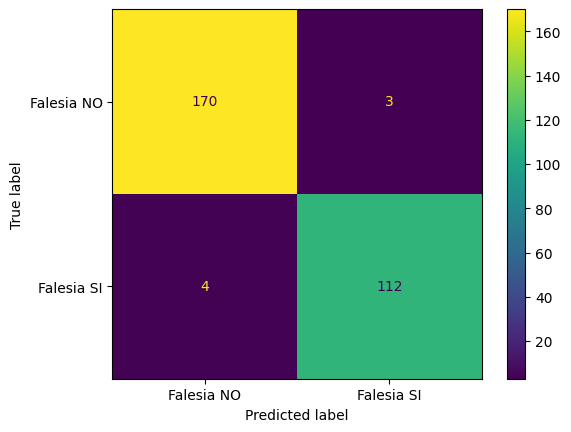

In [ ]:
cm = metrics.confusion_matrix(y_test, y_pred)
print(cm)
cmd = metrics.ConfusionMatrixDisplay(
    cm,
    display_labels=['Falesia NO', 'Falesia SI']
)
cmd.plot()

Precision Recall Curve

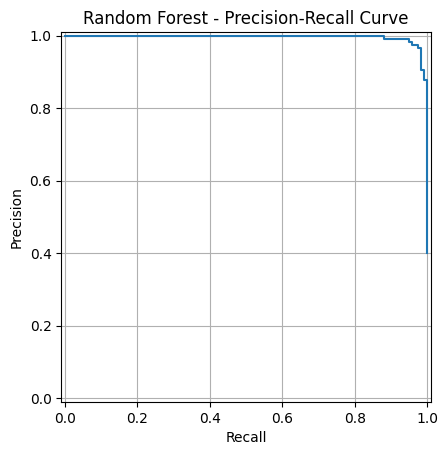

In [ ]:
y_prob = rf.predict_proba(X_test)[:, 1]

precision, recall, _ = metrics.precision_recall_curve(y_test, y_prob)

disp = metrics.PrecisionRecallDisplay(precision=precision, recall=recall)
disp.plot()
plt.title("Random Forest - Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True)

Report

In [ ]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy RF:", acc)

report = metrics.classification_report(
    y_test,
    y_pred,
    target_names=['Non Falesia', 'Falesia']
)

print("Report:")
print(report)

Accuracy RF: 0.9757785467128027
Report:
              precision    recall  f1-score   support

 Non Falesia       0.98      0.98      0.98       173
     Falesia       0.97      0.97      0.97       116

    accuracy                           0.98       289
   macro avg       0.98      0.97      0.97       289
weighted avg       0.98      0.98      0.98       289



# Secondo classificatore: Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

Standardizzazione dei dati

In [ ]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

In [ ]:
svm = SVC()

Addestramento con SVC

In [ ]:
svm.fit(X_train_std, y_train)

SVC()

In [ ]:
svm_predict = svm.predict(X_test_std)


Tabella metriche

In [ ]:
print("Accuracy SVM:", metrics.accuracy_score(y_test, svm_predict))
print("Report:")
print(
    metrics.classification_report(
        y_test,
        svm_predict,
        target_names=["Non Falesia", "Falesia"]
    )
)

Accuracy SVM: 0.8858131487889274
Report:
              precision    recall  f1-score   support

 Non Falesia       0.92      0.88      0.90       173
     Falesia       0.84      0.89      0.86       116

    accuracy                           0.89       289
   macro avg       0.88      0.89      0.88       289
weighted avg       0.89      0.89      0.89       289



Precision Recall Curve

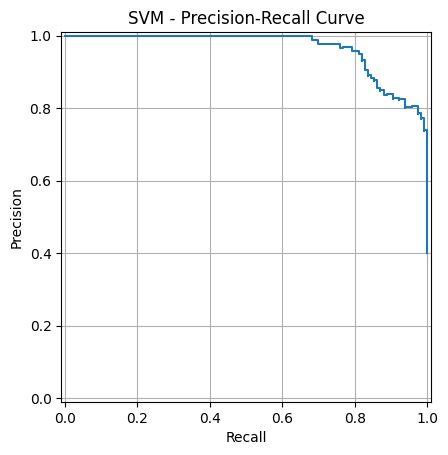

In [ ]:
svm_scores = svm.decision_function(X_test_std)


precision_svm, recall_svm, _ = metrics.precision_recall_curve(
    y_test,
    svm_scores
)


disp = metrics.PrecisionRecallDisplay(
    precision=precision_svm,
    recall=recall_svm
)
disp.plot()
plt.title("SVM - Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True)

Matrice di confusione

In [ ]:
cm = metrics.confusion_matrix(y_test, svm_predict)
print(cm)



[[153  20]
 [ 13 103]]


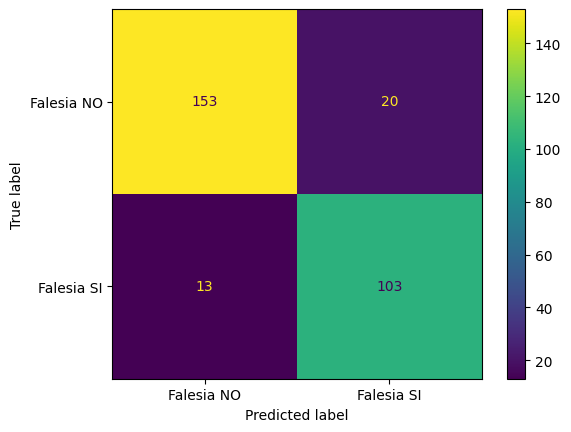

In [ ]:
cmd = metrics.ConfusionMatrixDisplay(
    cm,
    display_labels=['Falesia NO', 'Falesia SI']
)
cmd.plot()

# Salviamo e carichiamo il modello

In [ ]:
import joblib
joblib.dump(rf, "RF_default.pkl")
rf_trained = joblib.load("RF_default.pkl")

# Carichiamo il dataset di test

In [ ]:
df_real = pd.read_csv("/content/drive/MyDrive/Progetto GEODATA/dataset_definitivo.csv")
X_features = df_real[["DTM_elevat", 'roughness', 'slope', 'dissection', 'surfaceare', 'distance', 'litologia' ]]


In [ ]:
preds = rf_trained.predict(X_features)
probs = rf_trained.predict_proba(X_features).max(axis=1)

In [ ]:
df_output = df_real.copy()
df_output["Classe predetta"] = preds
df_output["Probabilità"] = probs

df_output.to_csv("rf_output_def.csv", index = False)